# SVM con un kernel propio (Jaccard ponderado)

Clasificación del nivel de riesgo de cáncer de pulmón (bajo, medio, alto) a partir de 22 variables ordinales de exposición y síntomas, con una máquina de vectores de soporte que usa un kernel de similitud construido a mano. Se revisa que el kernel sea válido, se proyectan los datos con Kernel PCA y se compara el modelo contra un SVM con kernel RBF.

Datos: [Cancer Patients and Air Pollution](https://www.kaggle.com/datasets/thedevastator/cancer-patients-and-air-pollution-a-new-link) (Kaggle), descargados con `kagglehub`.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.svm import SVC
from sklearn.decomposition import KernelPCA
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

## 1. Datos

Se descartan el índice, el identificador del paciente y la edad (la única variable continua); quedan el género y 21 variables ordinales de 1 a 9.

In [2]:
ruta = kagglehub.dataset_download('thedevastator/cancer-patients-and-air-pollution-a-new-link')
df = pd.read_csv(glob.glob(f'{ruta}/*.csv')[0])
df = df.drop(columns=['index', 'Patient Id', 'Age'])
print('Filas:', len(df))
print('Filas duplicadas:', df.duplicated().sum())
print('Perfiles repetidos con distinto nivel:', df.drop(columns='Level').duplicated().sum() - df.duplicated().sum())

Filas: 1000
Filas duplicadas: 916
Perfiles repetidos con distinto nivel: 0


De las 1.000 filas, solo 84 son perfiles distintos: el resto son copias exactas. Si se dejaran, el mismo paciente aparecería en entrenamiento y en prueba, y la evaluación mediría memoria, no generalización. Se trabaja con los 84 perfiles únicos.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
niveles = ['Low', 'Medium', 'High']
X = df.drop(columns='Level').to_numpy(dtype=float)
y = df['Level'].map({n: i for i, n in enumerate(niveles)}).to_numpy()
print('Perfiles únicos:', X.shape)
print(df['Level'].value_counts().reindex(niveles))

Perfiles únicos: (84, 22)
Level
Low       39
Medium    21
High      24
Name: count, dtype: int64


## 2. Kernel de Jaccard ponderado

Para vectores no negativos, la similitud de Jaccard ponderada (o de Ruzicka) es

$$k(x, z) = \frac{\sum_j \min(x_j, z_j)}{\sum_j \max(x_j, z_j)}$$

Vale 1 para perfiles idénticos y baja a medida que difieren en cada variable. Es un kernel válido (semidefinido positivo) para datos no negativos, lo que se comprueba abajo con los autovalores de la matriz de Gram.

Diagonal = 1: True
Simétrica: True
Autovalor mínimo: 4.13e-05 (semidefinida positiva si ≥ 0)


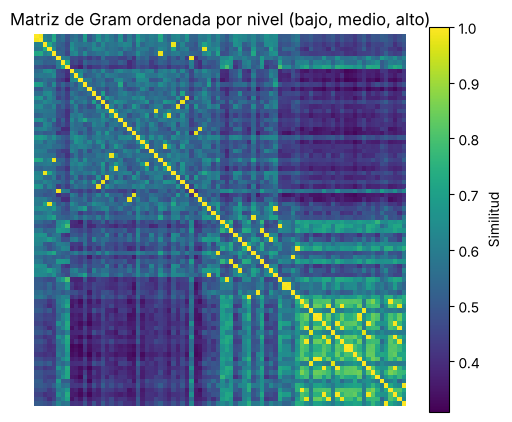

In [4]:
def kernel_jaccard(A, B):
    minimos = np.minimum(A[:, None, :], B[None, :, :]).sum(axis=2)
    maximos = np.maximum(A[:, None, :], B[None, :, :]).sum(axis=2)
    return minimos / maximos

K = kernel_jaccard(X, X)
autovalores = np.linalg.eigvalsh(K)
print(f'Diagonal = 1: {np.allclose(np.diag(K), 1)}')
print(f'Simétrica: {np.allclose(K, K.T)}')
print(f'Autovalor mínimo: {autovalores.min():.2e} (semidefinida positiva si ≥ 0)')

orden = np.argsort(y)
plt.figure(figsize=(6, 5))
plt.imshow(K[np.ix_(orden, orden)], cmap='viridis')
plt.colorbar(label='Similitud')
plt.title('Matriz de Gram ordenada por nivel (bajo, medio, alto)')
plt.axis('off')
plt.show()

## 3. Kernel PCA

Proyección en dos dimensiones usando el mismo kernel, para ver si los niveles se separan.

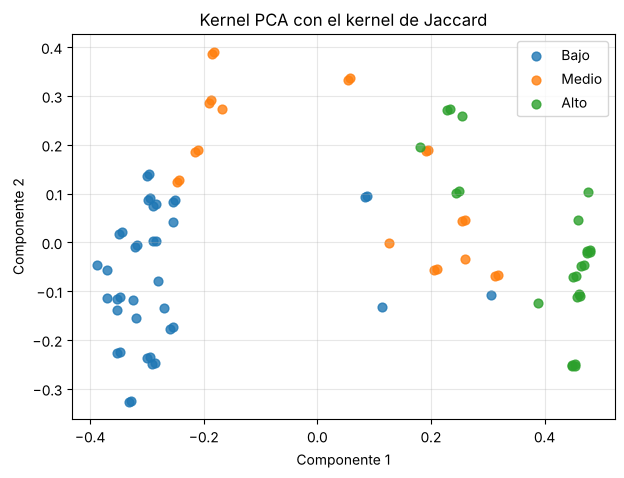

In [5]:
proy = KernelPCA(n_components=2, kernel='precomputed').fit_transform(K)
plt.figure(figsize=(7, 5))
for i, nombre in enumerate(['Bajo', 'Medio', 'Alto']):
    plt.scatter(*proy[y == i].T, label=nombre, s=40, alpha=0.8)
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.title('Kernel PCA con el kernel de Jaccard')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Clasificación

Con 84 perfiles, una sola partición de prueba (unos 25) da una exactitud muy ruidosa. Se usa validación cruzada estratificada de 5 pliegues, repetida con 10 semillas, y se compara con un SVM de kernel RBF sobre las variables estandarizadas.

In [6]:
svm_jaccard = SVC(kernel=kernel_jaccard)
svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf'))

for nombre, modelo in [('Jaccard', svm_jaccard), ('RBF', svm_rbf)]:
    puntajes = np.concatenate([
        cross_val_score(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s))
        for s in range(10)])
    print(f'SVM {nombre}: exactitud {puntajes.mean():.3f} ± {puntajes.std():.3f}')

SVM Jaccard: exactitud 0.855 ± 0.085
SVM RBF: exactitud 0.906 ± 0.072


              precision    recall  f1-score   support

        Bajo       0.92      0.90      0.91        39
       Medio       0.79      0.71      0.75        21
        Alto       0.85      0.96      0.90        24

    accuracy                           0.87        84
   macro avg       0.85      0.86      0.85        84
weighted avg       0.87      0.87      0.87        84



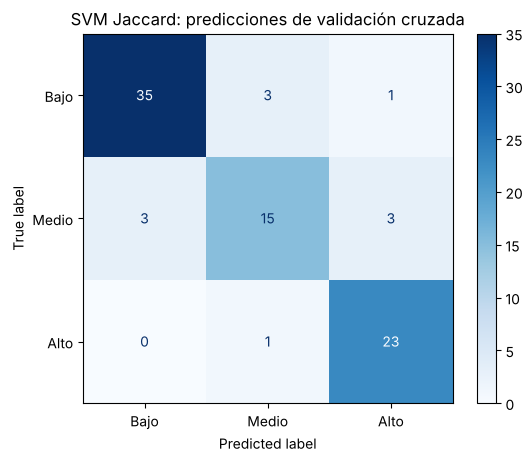

In [7]:
pred = cross_val_predict(svm_jaccard, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(classification_report(y, pred, target_names=['Bajo', 'Medio', 'Alto']))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=['Bajo', 'Medio', 'Alto'], cmap='Blues')
plt.title('SVM Jaccard: predicciones de validación cruzada')
plt.show()

**Análisis**

- El kernel de Jaccard es válido: la matriz de Gram es simétrica, tiene unos en la diagonal y ningún autovalor negativo. Ordenada por nivel, el bloque del nivel alto es el más marcado: esos perfiles se parecen mucho entre sí.
- En la proyección de Kernel PCA los niveles bajo y alto quedan en extremos opuestos del primer componente. El nivel medio se reparte en dos grupos, uno cerca del bajo y otro cerca del alto, y es el que más se mezcla.
- El SVM con el kernel propio acierta en promedio el 85,5 % en validación cruzada; el nivel medio es el que más confunde, coherente con la proyección.
- El kernel RBF estándar sobre las variables estandarizadas obtiene más (90,6 %). El kernel de Jaccard trata todas las variables con la misma escala y no aprende un ancho de banda; para estos datos ordinales, la distancia euclidiana con estandarización resulta más informativa. Con solo 84 perfiles, la dispersión entre pliegues (alrededor de ±8 puntos) es grande y la diferencia debe leerse con cautela.